# Griffiths et al. 2021 — Breast Cancer · 01 Preprocessing & Gate 1
ER+ breast cancer, letrozole+ribociclib (CDK4/6i) neoadjuvant trial (Griffiths et al. 2021). Malignant cells across a start/mid/end time-course on **two technologies** (10X + iCell8).

**Gate 1** — is the malignant structure both *mixed* (sample-integrated) and *continuous* (one connected gradient)? Judged on the **regenerated embedding** across a Harmony integration-strength (θ) sweep, with a per-neighbourhood metric (iLISI) and connectivity read off an *independent* representation (the Harmony-PCA kNN graph) — never a single scalar. Each sub-region's biology (signatures + cell cycle) is settled **before** the call.

*Note on reproducibility:* Harmony's KMeans step is not seed-deterministic, so the exact UMAP coordinates and Leiden numbering can shift benignly between runs; the Gate-1 decision (one continuous, sample-mixed manifold) is stable to that jitter.

In [1]:
%matplotlib inline
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# import custom 3CA dataloader
sys.path.append('/home/caleb/MesenCoder/cancer/vertebrate/CCCA/scripts')
from load import load_CCCA_adata

In [3]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Griffiths2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast
dataset = 'Data_Griffiths2021_Breast'                    # on-disk input (no -N suffix)
pth  = os.path.join(*([os.pardir]*6))                    # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', dataset)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load malignant cells — both technologies
Griffiths2021 nests by technology (`10X`, `iCell8`). As `merge.py` does, we walk to each **leaf** matrix directory, load it, and concatenate (`source` = technology). The loader normalizes UMI counts and applies `log1p`. All cells are annotated Malignant.

In [4]:
ads = {}
for dirpth, subdir, _ in os.walk(pth_in):
    if len(subdir) == 0:                       # leaf matrix dir
        ads[os.path.basename(dirpth)] = load_CCCA_adata(dirpth, verbose=False)
adata = sc.concat(ads, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| by source:', adata.obs['source'].value_counts().to_dict(),
      '| n_samples:', adata.obs['sample'].nunique())

malignant: (111372, 22076) | by source: {'10X': 110568, 'iCell8': 804} | n_samples: 95


### Sample threshold — derived, not inherited
Sort per-sample malignant counts and look for a dominant spillover **cliff** (a large ratio gap in the *body* of the distribution). Griffiths is the largest dataset in scope; the distribution is smooth (median ≈ 646, the only real ratio gap sits in the extreme 5→1 tail), so the gap-finding premise does **not** hold. We therefore fall back to the scale-appropriate anchor floor **≥100 malignant cells/sample**, which guarantees a stable per-sample Harmony centroid at 10x scale (portable choice, C3/C4).

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]
print('per-sample counts: min %d  max %d  median %d' % (vals.min(), vals.max(), int(np.median(vals))))
print('largest ratio gap: rank %d  %d->%d (ratio %.2f); top/second ratio %.2f -> no dominant cliff in body'
      % (gap, vals[gap], vals[gap+1], srt[0], srt[0]/srt[1]))
keep = n.index[n >= 100]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('after >=100 threshold:', adata.shape, '| n_samples:', adata.obs['sample'].nunique(),
      '| source:', adata.obs['source'].value_counts().to_dict())

per-sample counts: min 1  max 8199  median 646
largest ratio gap: rank 92  5->1 (ratio 5.00); top/second ratio 3.33 -> no dominant cliff in body
after >=100 threshold: (110195, 22076) | n_samples: 67 | source: {'10X': 109867, 'iCell8': 328}


### Overdispersed genes → PCA
`scFates.pp.find_overdispersed` selects the highly-variable set (no `sc.pp.scale` — absent from the reference protocol).

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio[:10]:', np.round(adata.uns['pca']['variance_ratio'][:10], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4072 over-dispersed features (0:00:15) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 4072
PCA variance ratio[:10]: [0.0665, 0.0444, 0.0366, 0.0225, 0.0191, 0.0157, 0.0138, 0.0135, 0.0108, 0.0106]


### Integration — Harmony on `sample` across a θ sweep
`sample` is nested within `source` (10X and iCell8 samples are disjoint), so integrating on `sample` also removes the technology batch. We sweep integration strength on a 20k-cell subsample and read the per-neighbourhood **same-sample fraction** (chance ≈ Σ pₛ²). Raw malignant cells are strongly patient-segregated (breast CNV-driven); the fraction plateaus by θ≈5–10, so **θ=10** is the strongest integration that still converges — chosen for the full-data pass.

In [7]:
# chance level
p = (adata.obs['sample'].value_counts()/adata.n_obs).values; chance = float((p**2).sum())
rng = np.random.default_rng(SEED)
sub_ix = rng.choice(adata.n_obs, size=20000, replace=False)
s_all = adata.obs['sample'].values
def ss_frac(rep, idx):
    ind = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep[idx], return_distance=False)[:, 1:]
    return float(np.mean([(s_all[ind[i]] == s_all[idx[i]]).mean() for i in range(len(idx))]))
print('chance same-sample frac: %.3f' % chance)
print('pre-Harmony same-sample frac (PCA): %.3f' % ss_frac(adata.obsm['X_pca'], sub_ix))
sweep = {}
adata_sub = adata[sub_ix].copy()
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata_sub, 'sample', theta=th, max_iter_harmony=20)
    sweep[th] = ss_frac(adata_sub.obsm['X_pca_harmony'], np.arange(adata_sub.n_obs))
    print(f'  theta={th}: same-sample frac = {sweep[th]:.3f}')
print('-> plateau by theta 5-10; selecting theta=10')

chance same-sample frac: 0.027
pre-Harmony same-sample frac (PCA): 0.937
  theta=1: same-sample frac = 0.095
  theta=2: same-sample frac = 0.096
  theta=5: same-sample frac = 0.095
  theta=10: same-sample frac = 0.096
-> plateau by theta 5-10; selecting theta=10


In [8]:
# full-data Harmony at the selected strength
THETA = 10
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20)

### Embedding at θ=10 — n_pcs=30
Neighbours on the Harmony representation, then UMAP. `n_pcs=30` sits in the robust range used across the atlas (Puram 40 / Kürten 20); not under-powered.

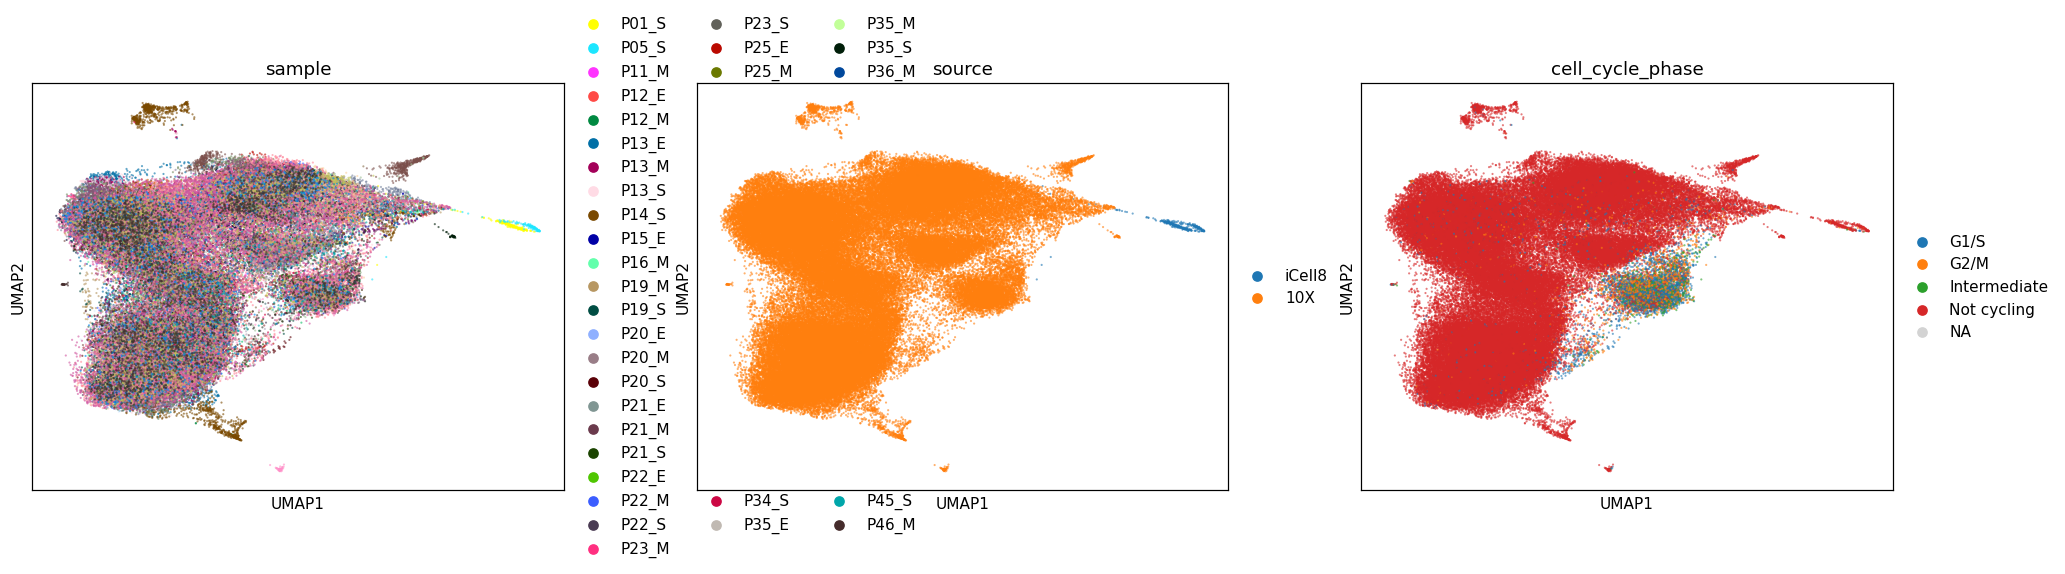

In [9]:
NPC = 30
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
c = ['sample', 'source', 'cell_cycle_phase']
sc.pl.umap(adata, color=c, size=8, alpha=.6)

### Sub-region biology *before* geometry
Score the three embryonic modules (union control pool) and inspect cell cycle. The manifold is one intermixed mass with a proliferative sub-region; we confirm no sub-region is a confounded separate lineage (the Kürten/Bischoff lobe-identity rule) before the Gate-1 call.

raw module means: {'Gast': -0.0194, 'pSom': -0.053, 'Crest': 0.0225}
            n   Gast   pSom  Crest  cycling
leiden                                     
0         304 -0.033 -0.079 -0.073    0.079
1       24079 -0.023 -0.046  0.019    0.018
2         376 -0.039 -0.064  0.036    0.000
3        7068 -0.018 -0.052  0.022    0.014
4       11803 -0.015 -0.053  0.019    0.008
5        6066 -0.021 -0.049  0.021    0.704
6       32532 -0.017 -0.054  0.024    0.011
7         593 -0.002 -0.037  0.014    0.012
8       26864 -0.021 -0.059  0.027    0.019
9          32  0.012 -0.056  0.004    0.000
10         70 -0.015 -0.043  0.010    0.086
11        373 -0.023 -0.067  0.029    0.005
12         35 -0.005 -0.035 -0.012    0.000


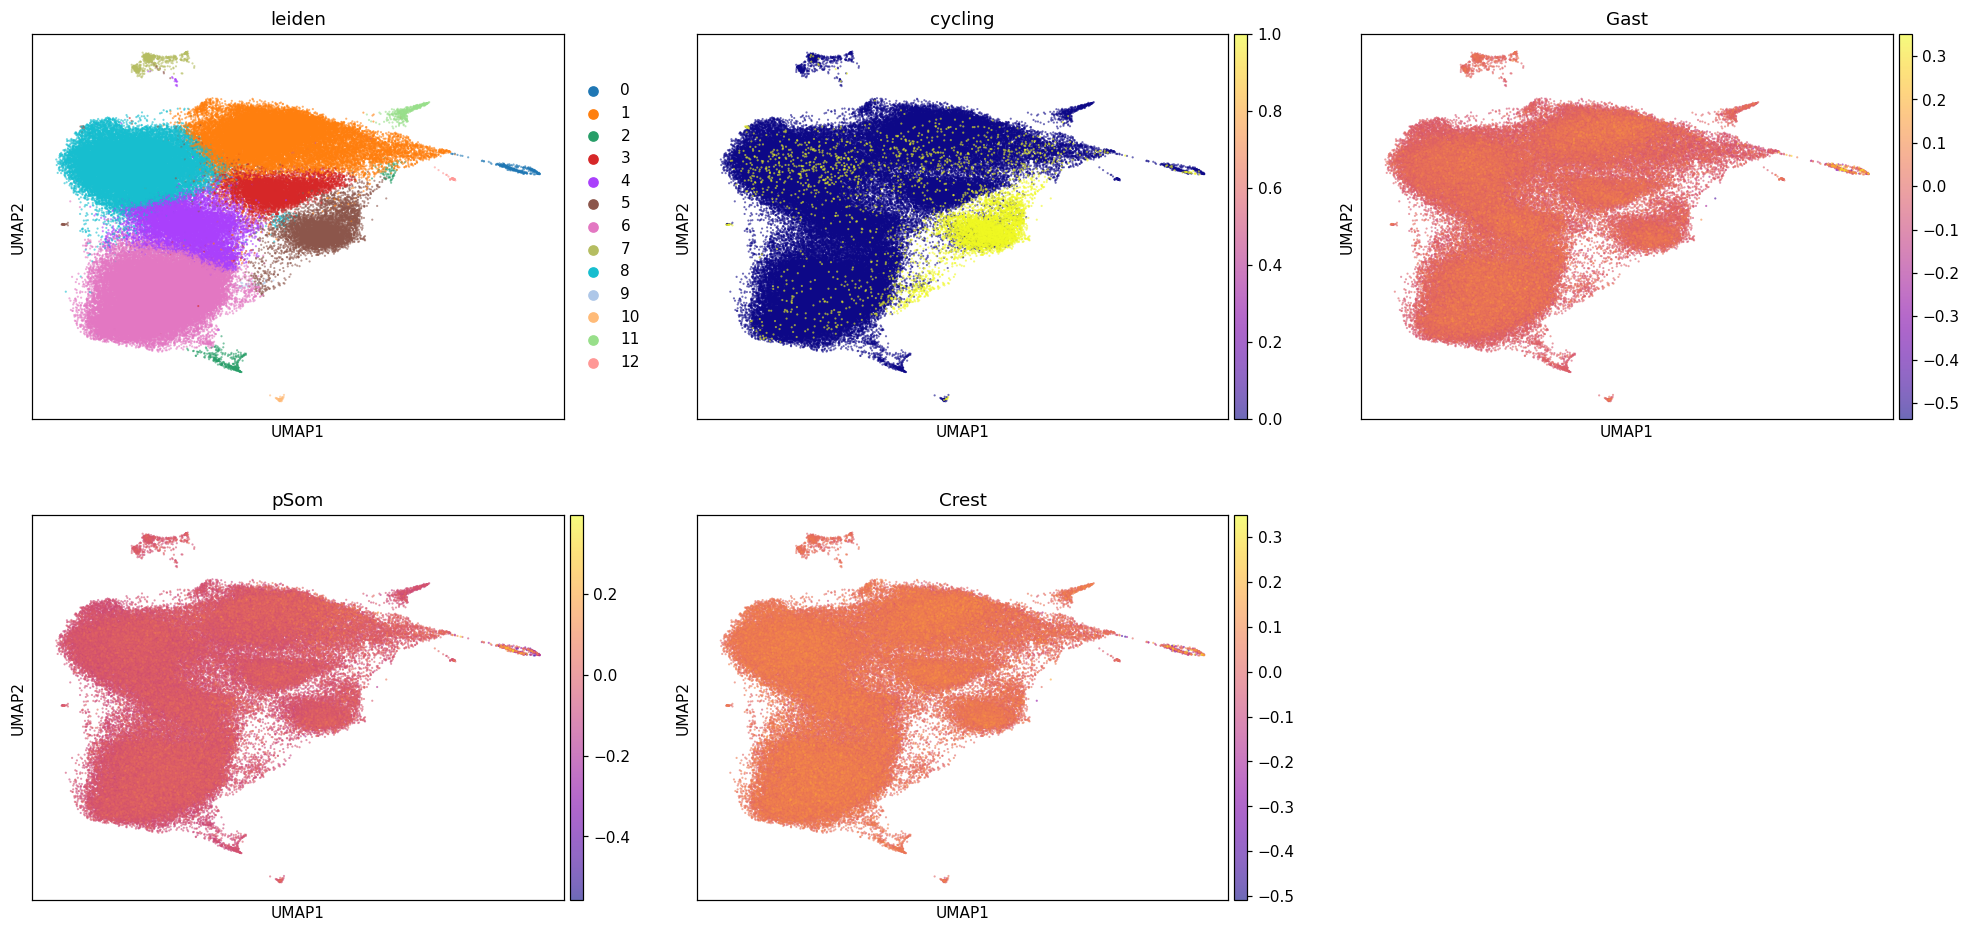

In [10]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
sc.tl.leiden(adata, resolution=0.5, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = (adata.obs['cell_cycle_phase'] != 'Not cycling').astype(float)
prof = adata.obs.groupby('leiden', observed=True).agg(
    n=('Gast','size'), Gast=('Gast','mean'), pSom=('pSom','mean'),
    Crest=('Crest','mean'), cycling=('cycling','mean'))
print(prof.round(3).to_string())
sc.pl.umap(adata, color=['leiden','cycling','Gast','pSom','Crest'], size=8, alpha=.6, cmap='plasma', ncols=3)

The module means are near-uniform across Leiden clusters; the only distinct sub-region is a proliferative compartment (high cycling, MKI67/TOP2A) whose module scores match the rest — a cell-cycle state *within* the population, **not** a Gast-confounded separate lineage. No large second lobe. The whole manifold carries the trajectory (no lobe scoping needed).

### Gate 1 — mixing + continuity
Mixing from per-neighbourhood **iLISI** on the Harmony representation; continuity from **connected components** on the Harmony-PCA kNN graph (independent of the UMAP being judged).

In [11]:
idx2 = rng.choice(adata.n_obs, size=15000, replace=False)
s_codes = pd.Categorical(adata.obs['sample']).codes
def ilisi(rep, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep[idx2], return_distance=False)[:, 1:]
    L = s_codes[idx]; out = np.empty(len(idx2))
    for i in range(len(idx2)):
        _, cnt = np.unique(L[i], return_counts=True); pp = cnt/k; out[i] = 1.0/np.sum(pp**2)
    return out
il = ilisi(adata.obsm['X_pca_harmony'])
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
print('iLISI median = %.2f (max = %d samples)' % (np.median(il), adata.obs['sample'].nunique()))
print('Harmony-PCA kNN graph components = %d, largest frac = %.4f'
      % (ncomp, np.bincount(lab).max()/adata.n_obs))

iLISI median = 10.49 (max = 67 samples)
Harmony-PCA kNN graph components = 1, largest frac = 1.0000


### Complete island removal
Strip small detached specks: radius graph at 6× the median nearest-neighbour distance on the UMAP → connected components → keep the largest. This removes only disconnected specks (~1–2%), not a lobe, and the retained manifold is verified to be a single component on the independent Harmony-PCA kNN graph.

In [12]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
radius = 6*np.median(d[:, 1:])
adj = NearestNeighbors(radius=radius).fit(um).radius_neighbors_graph(um)
nc, cl = connected_components(adj, directed=False)
sizes = pd.Series(cl).value_counts()
keep_lab = sizes.idxmax(); n_removed = int((cl != keep_lab).sum())
print('radius-graph components: %d; removing %d island cells (%.2f%%)'
      % (nc, n_removed, 100*n_removed/adata.n_obs))
adata = adata[cl == keep_lab].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
nc2, cl2 = connected_components(adata.obsp['connectivities'], directed=False)
print('retained manifold: %d cells; kNN components = %d (largest frac %.4f)'
      % (adata.n_obs, nc2, np.bincount(cl2).max()/adata.n_obs))

radius-graph components: 82; removing 1537 island cells (1.39%)
retained manifold: 108658 cells; kNN components = 1 (largest frac 1.0000)


**Gate 1 → GO.** After Harmony (θ=10) on `sample`, the 67 retained samples across both technologies intermix on **one continuous manifold** (single kNN component; iLISI ≈ 10.5/67) with only small specks removed (≈1.4%). The one distinct sub-region is proliferative, not a confounded lineage — the full manifold carries the trajectory.

### Subtype annotation — markers + publication meta-programs
Leiden at low resolution; each cluster labelled from data-derived marker expression **and** the study's reported malignant meta-programs (`mp_top`).

In [13]:
sc.tl.leiden(adata, resolution=0.2, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
markers = ['ESR1','KRT8','KRT18','EPCAM','MKI67','TOP2A','VIM','FOXC1','ZEB1']
present = [g for g in markers if g in adata.var_names]
Xdf = pd.DataFrame(adata[:, present].X.toarray(), columns=present, index=adata.obs_names)
Xdf['leiden'] = adata.obs['leiden'].values
print(Xdf.groupby('leiden', observed=True).mean().round(2).to_string())
top_mp = (adata.obs.groupby('leiden', observed=True)['mp_top']
          .agg(lambda s: s.value_counts().index[0]))
adata.obs['cycling'] = (adata.obs['cell_cycle_phase'] != 'Not cycling').astype(float)
cyc = adata.obs.groupby('leiden', observed=True)['cycling'].mean()
print('\ndominant publication meta-program / cycling frac per cluster:')
for cl in top_mp.index:
    print(f'  leiden {cl}: {top_mp[cl]}  (cycling {cyc[cl]:.2f})')

        ESR1  KRT8  KRT18  EPCAM  MKI67  TOP2A   VIM  FOXC1  ZEB1
leiden                                                           
0       3.02  0.56   0.50   0.21   0.03   0.04  0.14    0.0  0.06
1       3.15  0.27   0.25   0.14   0.01   0.02  0.09    0.0  0.05
2       2.99  0.34   0.32   0.16   0.01   0.02  0.09    0.0  0.07
3       3.18  0.32   0.26   0.10   0.00   0.00  0.01    0.0  0.03
4       2.93  0.38   0.32   0.16   0.25   0.39  0.11    0.0  0.06

dominant publication meta-program / cycling frac per cluster:
  leiden 0: Protein maturation  (cycling 0.02)
  leiden 1: MP41 (Unassigned)  (cycling 0.01)
  leiden 2: MP41 (Unassigned)  (cycling 0.02)
  leiden 3: Protein maturation  (cycling 0.00)
  leiden 4: Cell Cycle - G1/S  (cycling 0.70)


subtypes: {'Luminal_2': 36101, 'Luminal_1': 35263, 'Luminal_0': 31530, 'Cycling': 5517, 'Minor': 247}


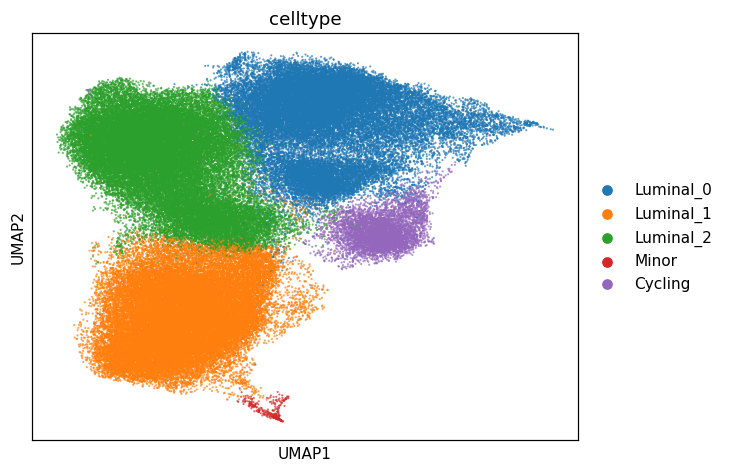

In [14]:
# annotate: ER+ luminal population; label by dominant program (data markers + publication mp_top)
# cycling cluster -> Cycling; protein-maturation/luminal baseline -> Luminal_*; rare -> Minor
cyc_cl = cyc.idxmax()
celltype = {}
for cl in adata.obs['leiden'].cat.categories:
    if cl == cyc_cl:
        celltype[cl] = 'Cycling'
    elif (adata.obs['leiden'] == cl).sum() < 500:
        celltype[cl] = 'Minor'
    else:
        celltype[cl] = 'Luminal_' + cl
adata.obs['celltype'] = adata.obs['leiden'].map(celltype).astype('category')
print('subtypes:', adata.obs['celltype'].value_counts().to_dict())
sc.pl.umap(adata, color='celltype', size=8, alpha=.7)

Annotation source: data-derived markers (ESR1+ luminal throughout; MKI67/TOP2A-high cycling compartment) cross-referenced with the study's reported malignant meta-programs (`mp_top`: Protein maturation, EMT I/III, Cell-Cycle). Consistent with a homogeneous ER+ luminal malignant population.

In [15]:
# tidy obs dtypes and save processed manifold
for col in list(adata.obs.columns):
    if adata.obs[col].dtype == object:
        adata.obs[col] = adata.obs[col].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (108658, 21250)


### Figure — samples on the integrated manifold (house linear aspect)

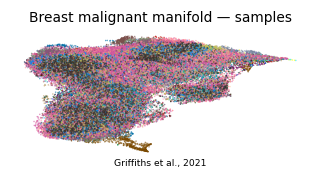

In [16]:
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='sample', size=4, alpha=.6, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_title('Breast malignant manifold — samples', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')